In [28]:
import h3
import numpy as np
import pandas as pd
import geopandas as gpd
import pystac_client
import planetary_computer
from shapely.geometry import Polygon, box
import rasterio
from rasterio.mask import mask
from rasterio.warp import calculate_default_transform, reproject, Resampling
import rasterstats
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns

In [2]:
from utils import (
    read_band,
    resample_band_to_10m,
    calculate_ndvi,
    calculate_ndwi,
    calculate_ndbi)
aoi_gdf = gpd.read_file("../data/kolkata_aoi.gpkg")
print(aoi_gdf.total_bounds, aoi_gdf.crs)

[88.25 22.5  88.45 22.7 ] EPSG:4326


In [3]:
catalog=pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1"
)
search=catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=aoi_gdf.total_bounds,
    datetime="2026-06-09/2026-06-09",
    query={"eo:cloud_cover": {"lt": 30}}
)
items=list(search.get_items())
item=planetary_computer.sign(items[0])
print(f"Selected scene: {item.datetime.date()}")

Selected scene: 2026-06-09


In [4]:
band_02, prof_02=read_band(item, "B02", aoi_gdf)
band_03, prof_03=read_band(item, "B03", aoi_gdf)
band_04, prof_04=read_band(item, "B04", aoi_gdf)
band_08, prof_08=read_band(item, "B08", aoi_gdf)
band_11, prof_11=read_band(item, "B11", aoi_gdf)
band_11=resample_band_to_10m(band_11, prof_11, prof_04)
ndvi=calculate_ndvi(band_08, band_04)
ndwi=calculate_ndwi(band_03, band_08)
ndbi=calculate_ndbi(band_11, band_08)
print("All bands and indices loaded.")
print("Grid:", ndvi.shape)

All bands and indices loaded.
Grid: (2080, 2076)


In [5]:
H3_RES=8
aoi_geojson=aoi_gdf.geometry.iloc[0].__geo_interface__
h3_cells=list(h3.geo_to_cells(aoi_geojson, res=H3_RES))
h3_gdf=gpd.GeoDataFrame({"h3_id": h3_cells,"geometry": [Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(cell)])for cell in h3_cells]},crs="EPSG:4326")
print(f"H3 cells: {len(h3_gdf)}")
h3_gdf.head()

H3 cells: 565


,h3_id,geometry
0,883cf2c6adfffff,"POLYGON ((88.42997 22.54143, 88.43025 22.5464,..."
1,883cf2c637fffff,"POLYGON ((88.40162 22.542, 88.4019 22.54697, 8..."
2,883cf28929fffff,"POLYGON ((88.40499 22.60163, 88.40528 22.6066,..."
3,883cf2d495fffff,"POLYGON ((88.36803 22.61728, 88.36831 22.62225..."
4,883cf2d581fffff,"POLYGON ((88.31312 22.56613, 88.31339 22.5711,..."


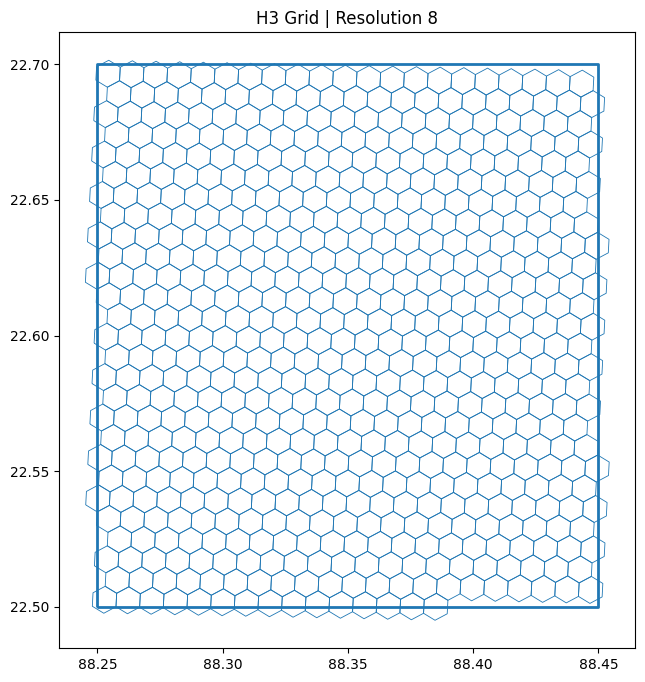

In [6]:
fig, ax = plt.subplots(figsize=(8, 8))

h3_gdf.boundary.plot(ax=ax, linewidth=0.6)
aoi_gdf.boundary.plot(ax=ax, linewidth=2)

ax.set_title(f"H3 Grid | Resolution {H3_RES}")
plt.show()

In [7]:
h3_raster=h3_gdf.to_crs(prof_04["crs"])
index_stats=[]
for _, row in h3_raster.iterrows():
    ndvi_s = rasterstats.zonal_stats(row.geometry,ndvi,affine=prof_04["transform"],stats=["mean", "std", "count"],nodata=np.nan)[0]
    ndwi_s = rasterstats.zonal_stats(row.geometry,ndwi,affine=prof_04["transform"],stats=["mean", "std"])[0]
    ndbi_s=rasterstats.zonal_stats(row.geometry,ndbi,affine=prof_04["transform"],stats=["mean", "std"])[0]
    if ndvi_s["count"] > 0:
        index_stats.append({
            "h3_id": row.h3_id,
            "ndvi_mean": ndvi_s["mean"],
            "ndvi_std": ndvi_s["std"],
            "ndwi_mean": ndwi_s["mean"],
            "ndwi_std": ndwi_s["std"],
            "ndbi_mean": ndbi_s["mean"],
            "ndbi_std": ndbi_s["std"],
            "pixel_count": ndvi_s["count"]
        })
index_df=pd.DataFrame(index_stats)
print(f"Aggregated H3 cells: {len(index_df)}")
index_df.head()

Aggregated H3 cells: 540


,h3_id,ndvi_mean,ndvi_std,ndwi_mean,ndwi_std,ndbi_mean,ndbi_std,pixel_count
0,883cf2c6adfffff,0.263712,0.180948,-0.230028,0.165224,-0.130051,0.121101,8034
1,883cf2c637fffff,0.208531,0.140419,-0.200323,0.117561,-0.045443,0.102079,8030
2,883cf28929fffff,0.152805,0.114322,-0.161642,0.095170,0.029457,0.086507,8030
3,883cf2d495fffff,-0.080458,0.167529,0.099192,0.171121,-0.000909,0.063441,8022
4,883cf2d581fffff,0.195267,0.133496,-0.188245,0.105713,-0.001350,0.102937,8026


In [16]:
pop_path = "../data/IND_DUG_2026_GRID_L2_R2025A_v1.tif"
with rasterio.open(pop_path) as src:
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Shape:", (src.height, src.width))
    print("Bounds:", src.bounds)

CRS: ESRI:54009
Resolution: (1000.0, 1000.0)
Shape: (3448, 2904)
Bounds: BoundingBox(left=6469000.0, bottom=834000.0, right=9373000.0, top=4282000.0)


In [17]:
from rasterio.windows import from_bounds
with rasterio.open(pop_path) as src:
    aoi_proj=aoi_gdf.to_crs(src.crs)
    window=from_bounds(*aoi_proj.total_bounds, transform=src.transform)
    urban=src.read(1, window=window)
    urban_transform=src.window_transform(window)
print("Urbanisation shape:", urban.shape)
print("Unique values:", np.unique(urban))

Urbanisation shape: (24, 27)
Unique values: [30]


In [18]:
urban_path="../data/IND_DUG_2026_GRID_L1_R2025A_v1.tif"
with rasterio.open(urban_path) as src:
    aoi_proj=aoi_gdf.to_crs(src.crs)
    window=from_bounds(*aoi_proj.total_bounds, transform=src.transform)
    urban_l1=src.read(1, window=window)
print("Shape:", urban_l1.shape)
print("Unique values:", np.unique(urban_l1))

Shape: (24, 27)
Unique values: [3]


In [19]:
h3_raster=h3_gdf.to_crs(prof_04["crs"])
stats=[]
for _, row in h3_raster.iterrows():
    s=rasterstats.zonal_stats(row.geometry, ndvi,affine=prof_04["transform"],stats=["mean", "std", "count"],nodata=np.nan)[0]
    w=rasterstats.zonal_stats(row.geometry, ndwi,affine=prof_04["transform"],stats=["mean", "std"])[0]
    b=rasterstats.zonal_stats(row.geometry, ndbi,affine=prof_04["transform"],stats=["mean", "std"])[0]
    stats.append({
        "h3_id": row.h3_id,
        "ndvi_mean": s["mean"],
        "ndvi_std": s["std"],
        "ndwi_mean": w["mean"],
        "ndwi_std": w["std"],
        "ndbi_mean": b["mean"],
        "ndbi_std": b["std"],
        "pixel_count": s["count"]
    })
index_df=pd.DataFrame(stats)
print(index_df.shape)
index_df.head()

(565, 8)


,h3_id,ndvi_mean,ndvi_std,ndwi_mean,ndwi_std,ndbi_mean,ndbi_std,pixel_count
0,883cf2c6adfffff,0.263712,0.180948,-0.230028,0.165224,-0.130051,0.121101,8034
1,883cf2c637fffff,0.208531,0.140419,-0.200323,0.117561,-0.045443,0.102079,8030
2,883cf28929fffff,0.152805,0.114322,-0.161642,0.095170,0.029457,0.086507,8030
3,883cf2d495fffff,-0.080458,0.167529,0.099192,0.171121,-0.000909,0.063441,8022
4,883cf2d581fffff,0.195267,0.133496,-0.188245,0.105713,-0.001350,0.102937,8026


In [21]:
h3_df = h3_gdf.merge(index_df, on="h3_id")
print(h3_df.shape)
ml_df = h3_df.drop(columns="geometry").dropna()

print(ml_df.shape)
ml_df.head()

(565, 9)
(540, 8)


,h3_id,ndvi_mean,ndvi_std,ndwi_mean,ndwi_std,ndbi_mean,ndbi_std,pixel_count
0,883cf2c6adfffff,0.263712,0.180948,-0.230028,0.165224,-0.130051,0.121101,8034
1,883cf2c637fffff,0.208531,0.140419,-0.200323,0.117561,-0.045443,0.102079,8030
2,883cf28929fffff,0.152805,0.114322,-0.161642,0.095170,0.029457,0.086507,8030
3,883cf2d495fffff,-0.080458,0.167529,0.099192,0.171121,-0.000909,0.063441,8022
4,883cf2d581fffff,0.195267,0.133496,-0.188245,0.105713,-0.001350,0.102937,8026


In [33]:
np.random.seed(726)
sample_size=min(50, len(h3_df))
labeled_cells=h3_df.sample(sample_size, random_state=42).copy()
print(f"Selected {len(labeled_cells)} H3 cells")
print(labeled_cells[["h3_id", "ndvi_mean", "ndwi_mean", "ndbi_mean"]].head())

Selected 50 H3 cells
               h3_id  ndvi_mean  ndwi_mean  ndbi_mean
538  883cf2c759fffff   0.340598  -0.302072  -0.095270
523  883cf2d689fffff   0.337167  -0.290124  -0.134260
234  883cf2d419fffff   0.272751  -0.251317  -0.059788
524  883cf2882bfffff   0.193601  -0.194121   0.000354
486  883cf2d69dfffff   0.288626  -0.243416  -0.139813


RGB shape: (2080, 2076, 3)


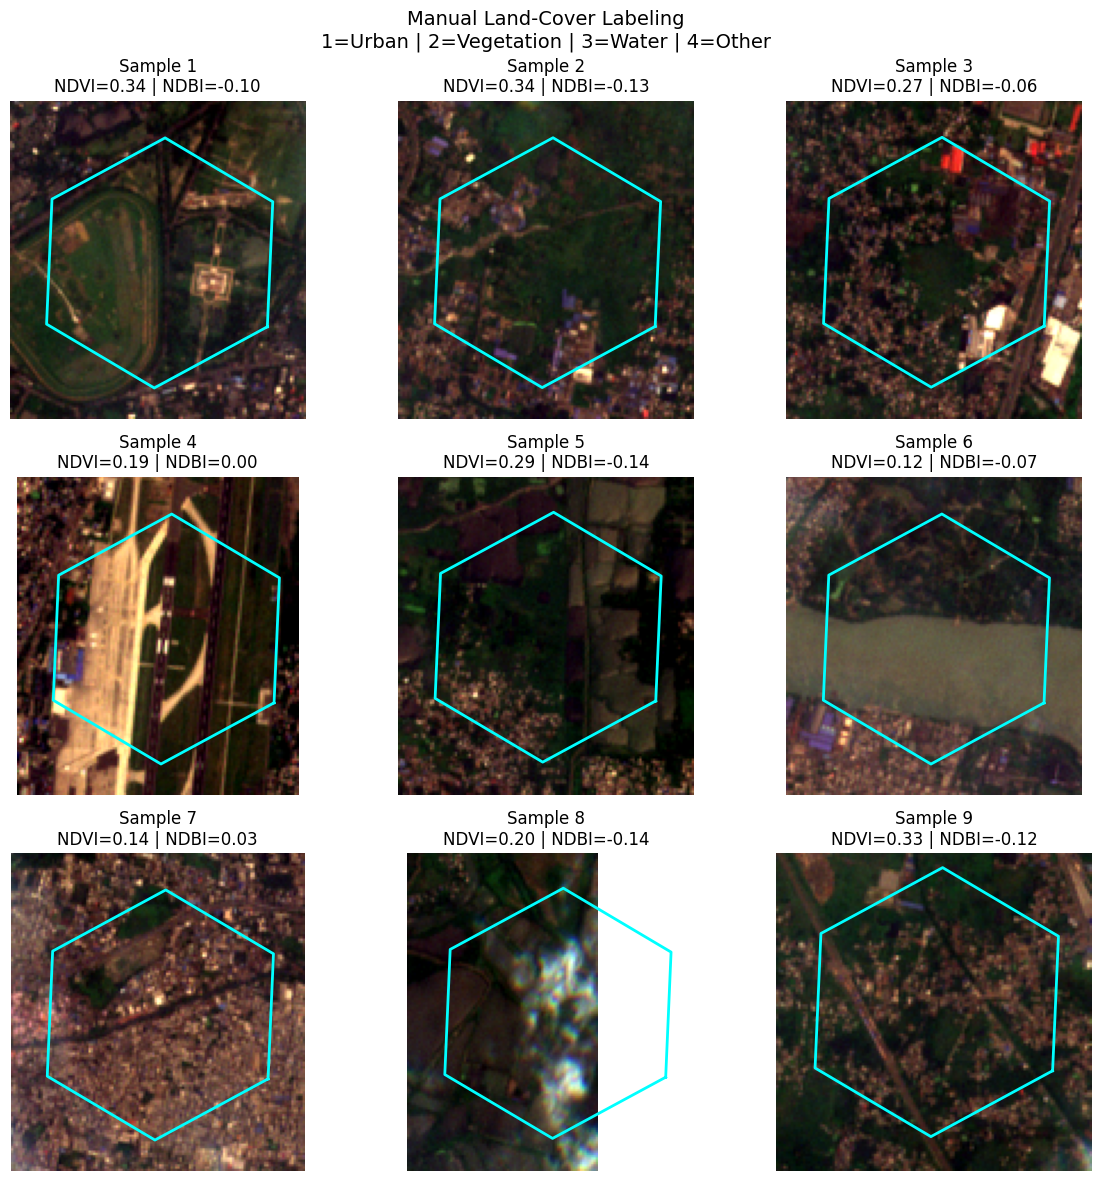

In [38]:
def stretch(array):
    low, high = np.nanpercentile(array, [2, 98])
    return np.clip((array - low) / (high - low), 0, 1)

rgb = np.dstack([
    stretch(band_04),
    stretch(band_03),
    stretch(band_02)
])

print("RGB shape:", rgb.shape)

# Cell 15B: Display cells with simple sample numbers

from rasterio.windows import from_bounds
from matplotlib.patches import Polygon as mplPolygon

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes = axes.ravel()

for sample_no, (ax, (_, cell)) in enumerate(
    zip(axes, labeled_cells.iloc[:9].iterrows()), start=1
):

    cell_proj = gpd.GeoSeries(
        [cell.geometry],
        crs="EPSG:4326"
    ).to_crs(prof_04["crs"]).iloc[0]

    window = from_bounds(
        *cell_proj.bounds,
        transform=prof_04["transform"]
    )

    margin = 15
    r0 = max(0, int(window.row_off) - margin)
    c0 = max(0, int(window.col_off) - margin)
    r1 = min(rgb.shape[0], int(window.row_off + window.height) + margin)
    c1 = min(rgb.shape[1], int(window.col_off + window.width) + margin)

    crop = rgb[r0:r1, c0:c1]
    ax.imshow(crop)

    coords = np.array(cell_proj.exterior.coords)
    xs, ys = [], []

    for x, y in coords:
        col, row = ~prof_04["transform"] * (x, y)
        xs.append(col - c0)
        ys.append(row - r0)

    ax.plot(xs, ys, color="cyan", linewidth=2)

    ax.set_title(
        f"Sample {sample_no}\n"
        f"NDVI={cell.ndvi_mean:.2f} | NDBI={cell.ndbi_mean:.2f}"
    )
    ax.axis("off")

plt.suptitle(
    "Manual Land-Cover Labeling\n"
    "1=Urban | 2=Vegetation | 3=Water | 4=Other",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [39]:
# Cell 16: Find ESA WorldCover reference data

search_wc = catalog.search(
    collections=["esa-worldcover"],
    bbox=aoi_gdf.total_bounds,
    datetime="2021-01-01/2021-12-31"
)

wc_items = list(search_wc.get_items())

print(f"WorldCover items found: {len(wc_items)}")

if wc_items:
    wc_item = planetary_computer.sign(wc_items[0])
    print("Selected:", wc_item.id)
    print("Assets:", list(wc_item.assets.keys()))

WorldCover items found: 1
Selected: ESA_WorldCover_10m_2021_v200_N21E087
Assets: ['map', 'input_quality', 'tilejson', 'rendered_preview']


In [41]:
wc_href = wc_item.assets["map"].href
with rasterio.open(wc_href) as src:
    wc = src.read(1)
    wc_profile = src.profile
print("WorldCover shape:", wc.shape)
print("WorldCover CRS:", wc_profile["crs"])
print("WorldCover resolution:", wc_profile["transform"].a, abs(wc_profile["transform"].e))
print("WorldCover classes:", np.unique(wc))

WorldCover shape: (36000, 36000)
WorldCover CRS: EPSG:4326
WorldCover resolution: 8.333333333333333e-05 8.333333333333333e-05
WorldCover classes: [ 0 10 20 30 40 50 60 80 90 95]


In [42]:
# Cell 18: Crop WorldCover to the AOI
from rasterio.windows import from_bounds

with rasterio.open(wc_href) as src:
    aoi_wc = aoi_gdf.to_crs(src.crs)

    window = from_bounds(
        *aoi_wc.total_bounds,
        transform=src.transform
    )

    wc_aoi = src.read(1, window=window)
    wc_transform = src.window_transform(window)

print("AOI WorldCover shape:", wc_aoi.shape)
print("Classes in AOI:", np.unique(wc_aoi))
# 1 = Urban
# 2 = Vegetation
# 3 = Water
# 4 = Other

class_map = {
    10: 2,   # Tree cover       -> Vegetation
    20: 2,   # Shrubland        -> Vegetation
    30: 2,   # Grassland        -> Vegetation
    40: 2,   # Cropland         -> Vegetation
    50: 1,   # Built-up         -> Urban
    60: 4,   # Bare/sparse      -> Other
    80: 3,   # Water            -> Water
    90: 3,   # Wetland          -> Water
    95: 2    # Mangroves        -> Vegetation
}

wc_project = np.full(wc_aoi.shape, np.nan)

for wc_class, project_class in class_map.items():
    wc_project[wc_aoi == wc_class] = project_class

print("Project classes:", np.unique(wc_project[~np.isnan(wc_project)]))

AOI WorldCover shape: (2400, 2400)
Classes in AOI: [10 20 30 40 50 60 80 90]
Project classes: [1. 2. 3. 4.]


In [45]:
# Cell 20: Assign majority WorldCover class to each H3 cell

h3_wc = h3_gdf.to_crs(wc_profile["crs"])

label_records = []

for _, row in h3_wc.iterrows():

    stats = rasterstats.zonal_stats(
        row.geometry,
        wc_project,
        affine=wc_transform,
        categorical=True,
        nodata=np.nan
    )[0]

    # Keep only the four valid project classes
    counts = {}

    for key, value in stats.items():
        try:
            key = int(key)
            if key in [1, 2, 3, 4]:
                counts[key] = int(value)
        except (ValueError, TypeError):
            continue

    if counts:
        label = max(counts, key=counts.get)

        label_records.append({
            "h3_id": row.h3_id,
            "label": label
        })

labels_manual = pd.DataFrame(label_records)

print("Labeled H3 cells:", len(labels_manual))
print("\nLabel distribution:")
print(labels_manual["label"].value_counts().sort_index())

Labeled H3 cells: 565

Label distribution:
label
1    343
2    185
3     37
Name: count, dtype: int64


In [47]:
# Cell 21: Extract mean Sentinel-2 features for each H3 cell

h3_utm = h3_gdf.to_crs(prof_04["crs"])

feature_records = []

for _, row in h3_utm.iterrows():

    features = {}

    for name, array in {
        "B02": band_02,
        "B03": band_03,
        "B04": band_04,
        "B08": band_08,
        "B11": band_11,
        "NDVI": ndvi,
        "NDWI": ndwi,
        "NDBI": ndbi
    }.items():

        # Use NaN only for floating-point arrays
        raster = array.astype(np.float32)

        stats = rasterstats.zonal_stats(
            row.geometry,
            raster,
            affine=prof_04["transform"],
            stats=["mean"]
        )[0]

        features[name + "_mean"] = stats["mean"]

    features["h3_id"] = row.h3_id
    feature_records.append(features)

features_df = pd.DataFrame(feature_records)

print("Feature table shape:", features_df.shape)
print(features_df.head())

Feature table shape: (565, 9)
      B02_mean     B03_mean     B04_mean     B08_mean     B11_mean  NDVI_mean  \
0  1928.604805  2182.360219  2025.911626  3730.653722  2781.339806   0.263712   
1  2121.075965  2328.314819  2296.934994  3578.053549  3213.993026   0.208531   
2  2188.970361  2368.495143  2424.494645  3309.645330  3488.147945   0.152805   
3  2332.294690  2604.429818  2505.301421  2222.987784  2181.210920  -0.080458   
4  2213.188637  2390.019686  2360.208074  3569.394966  3507.507849   0.195267   

   NDWI_mean  NDBI_mean            h3_id  
0  -0.230028  -0.130051  883cf2c6adfffff  
1  -0.200323  -0.045443  883cf2c637fffff  
2  -0.161642   0.029457  883cf28929fffff  
3   0.099192  -0.000909  883cf2d495fffff  
4  -0.188245  -0.001350  883cf2d581fffff  


In [48]:
# Cell 22: Create final ML dataset

ml_df = features_df.merge(
    labels_manual,
    on="h3_id",
    how="inner"
).dropna()

print("ML dataset:", ml_df.shape)
print("\nLabels:")
print(ml_df["label"].value_counts().sort_index())

ML dataset: (540, 10)

Labels:
label
1    328
2    175
3     37
Name: count, dtype: int64


In [49]:
feature_cols = [
    "B02_mean",
    "B03_mean",
    "B04_mean",
    "B08_mean",
    "B11_mean",
    "NDVI_mean",
    "NDWI_mean",
    "NDBI_mean"
]
X=ml_df[feature_cols]
y=ml_df["label"]
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.20,random_state=726,stratify=y)
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)
print("Training:", X_train.shape)
print("Testing:", X_test.shape)
print("\nTraining labels:")
print(y_train.value_counts().sort_index())
print("\nTesting labels:")
print(y_test.value_counts().sort_index())

Training: (432, 8)
Testing: (108, 8)

Training labels:
label
1    262
2    140
3     30
Name: count, dtype: int64

Testing labels:
label
1    66
2    35
3     7
Name: count, dtype: int64


In [ ]:
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
rf=RandomForestClassifier(n_estimators=100,random_state=726)
rf.fit(X_train, y_train)

In [52]:
knn_pred=knn.predict(X_test_scaled)
rf_pred=rf.predict(X_test)
knn_acc=accuracy_score(y_test, knn_pred)
rf_acc=accuracy_score(y_test, rf_pred)
print(f"KNN Accuracy: {knn_acc:.3f}")
print(f"Random Forest Accuracy: {rf_acc:.3f}")
print("\nKNN Classification Report")
print(classification_report(y_test,knn_pred,target_names=["Urban", "Vegetation", "Water"],zero_division=0))
print("\nRandom Forest Classification Report")
print(classification_report(y_test,rf_pred,target_names=["Urban", "Vegetation", "Water"],zero_division=0))

KNN Accuracy: 0.917
Random Forest Accuracy: 0.898

KNN Classification Report
              precision    recall  f1-score   support

       Urban       0.91      0.97      0.94        66
  Vegetation       0.94      0.86      0.90        35
       Water       0.83      0.71      0.77         7

    accuracy                           0.92       108
   macro avg       0.90      0.85      0.87       108
weighted avg       0.92      0.92      0.92       108


Random Forest Classification Report
              precision    recall  f1-score   support

       Urban       0.94      0.91      0.92        66
  Vegetation       0.86      0.91      0.89        35
       Water       0.71      0.71      0.71         7

    accuracy                           0.90       108
   macro avg       0.84      0.85      0.84       108
weighted avg       0.90      0.90      0.90       108



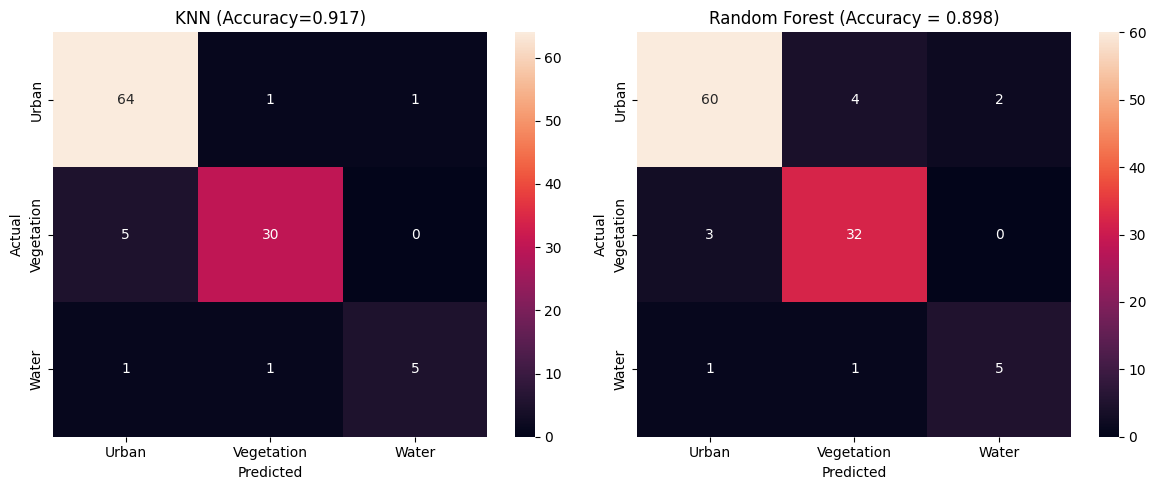

In [53]:
labels=["Urban", "Vegetation", "Water"]
cm_knn=confusion_matrix(y_test, knn_pred)
cm_rf=confusion_matrix(y_test, rf_pred)
fig, axes=plt.subplots(1,2,figsize=(12,5))
sns.heatmap(cm_knn,annot=True,fmt="d",xticklabels=labels,yticklabels=labels,ax=axes[0])
axes[0].set_title(f"KNN (Accuracy={knn_acc:.3f})")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
sns.heatmap(cm_rf,annot=True,fmt="d",xticklabels=labels,yticklabels=labels,ax=axes[1])
axes[1].set_title(f"Random Forest (Accuracy = {rf_acc:.3f})")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [54]:
X_full=features_df[feature_cols].dropna()
X_full_scaled=scaler.transform(X_full)
full_predictions=knn.predict(X_full_scaled)
prediction_df=features_df.loc[X_full.index, ["h3_id"]].copy()
prediction_df["land_cover"]=full_predictions
label_map={1: "Urban",2: "Vegetation",3: "Water",4: "Other"}
prediction_df["land_cover_name"]=(prediction_df["land_cover"].map(label_map))
print(prediction_df["land_cover_name"].value_counts())

land_cover_name
Urban         347
Vegetation    160
Water          33
Name: count, dtype: int64


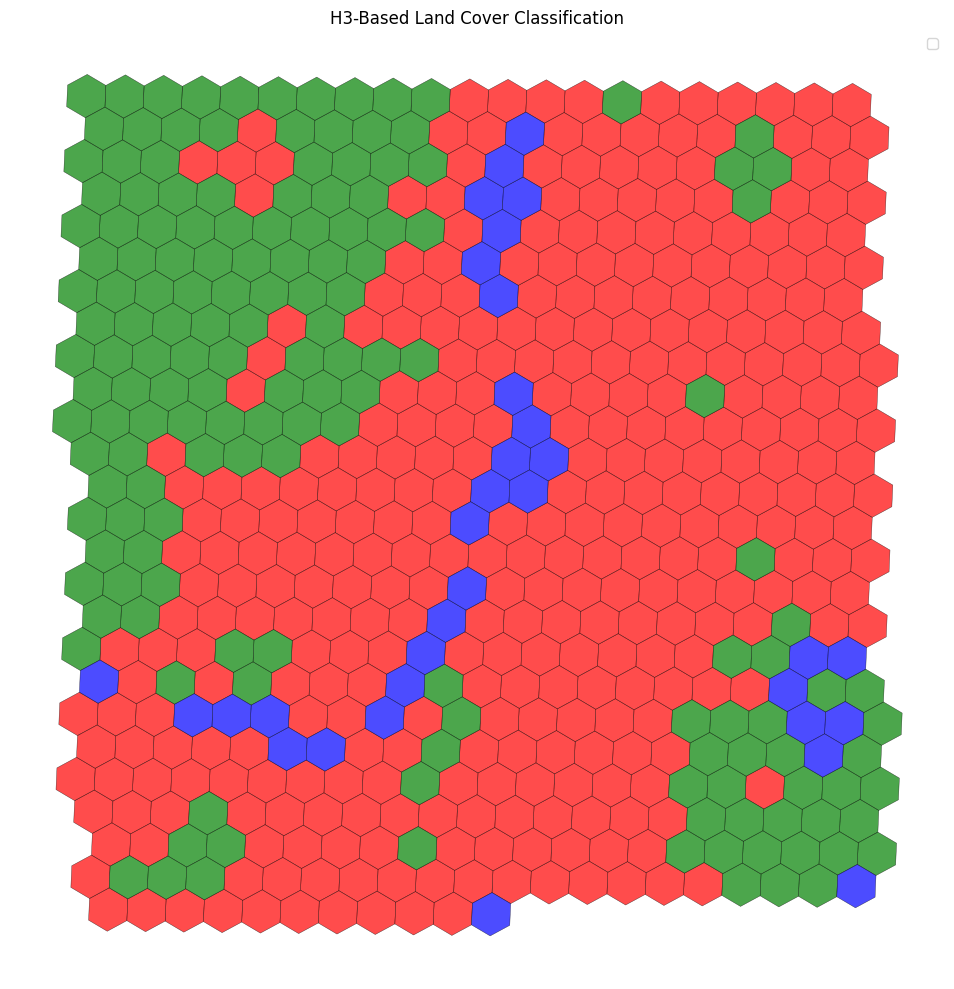

In [60]:
final_map_plot=final_map.to_crs("EPSG:32645")
colors={
    1: "red",       # Urban
    2: "green",     # Vegetation
    3: "blue",      # Water
    4: "gray"       # Other
}
fig,ax=plt.subplots(figsize=(10, 10))
for label,name in label_map.items():
    subset=final_map_plot[final_map_plot["land_cover"]==label]
    if len(subset)>0:
        subset.plot(ax=ax,color=colors[label],alpha=0.7,edgecolor="black",linewidth=0.3,label=name)
ax.set_title("H3-Based Land Cover Classification")
ax.legend()
ax.axis("off")
plt.tight_layout()
plt.show()

In [62]:
final_map.to_file("../data/h3_land_cover_predictions.gpkg",driver="GPKG")
prediction_df.to_csv("../data/h3_land_cover_predictions.csv",index=False)
print("Final outputs saved successfully")

Final outputs saved successfully
